In [ ]:
%cd ..

In [ ]:
import json
from pathlib import Path

data_dir = Path("data/epn612/trainingJSON")

fpath = data_dir / "user1" / "user1.json"
with open(fpath, "r") as f:
    data = json.load(f)

print(data.keys())

In [ ]:
print(data['generalInfo'])
print(data['userInfo'])
print(data['userInfo'].keys())
print(data['synchronizationGesture']['samples'].keys())
print(data['trainingSamples'].keys())

In [ ]:
print(data['synchronizationGesture']['samples']['idx_1'])
print(data['trainingSamples']['idx_1'])

In [ ]:
import numpy as np

sample1 = data['synchronizationGesture']['samples']['idx_1']['myoDetection']
sample2 = data['trainingSamples']['idx_1']['myoDetection']

sample1 = np.array(sample1)
sample2 = np.array(sample2)

print(sample1.shape)
print(sample2.shape)
print(sample1.mean())
print(sample2.mean())
print(sample1.std())
print(sample2.std())

In [ ]:

def print_key_tree(d, indent=0):
    for k, v in d.items():
        print("  " * indent + str(k))
        if isinstance(v, dict):
            print_key_tree(v, indent + 1)

In [ ]:
print_key_tree(data['trainingSamples']['idx_1'])

In [ ]:
for x in data['trainingSamples']:
    print(x)
    print(data['trainingSamples'][x].keys())
    print(data['trainingSamples'][x]['emg'].keys())
    ch1 = data['trainingSamples'][x]['emg']['ch1']
    ch1 = np.array(ch1)
    print(ch1.shape)
    print(ch1.mean())
    print(ch1.std())
    print(np.max(np.abs(ch1)))

    acc = data['trainingSamples'][x]['accelerometer']
    print(acc.keys())
    xaxis = np.array(acc['x'])

    print(xaxis.shape)
    print(xaxis.mean())
    print(xaxis.std())
    

In [ ]:
# %cd ..

In [3]:
%cd ..

/home/willraftery/PhD/projects/github/emg-stream


In [2]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter
from tqdm import tqdm

# Set plotting style
plt.style.use('seaborn-v0_8-muted')
sns.set_context("talk")

def perform_emg_audit(hdf5_path, root_key="epn612"):
    """
    Performs a full audit of the standardized HDF5 file.
    Analyzes demographics, class balance, and split leakage.
    """
    hdf5_path = Path(hdf5_path)
    if not hdf5_path.exists():
        raise FileNotFoundError(f"Could not find HDF5 at {hdf5_path}")

    rows = []
    
    with h5py.File(hdf5_path, 'r') as f:
        root = f[root_key]
        
        # 1. Crawl all Subjects and Sessions
        for subj_id in tqdm(root.keys(), desc="Auditing Subjects"):
            subj_group = root[subj_id]
            subj_attrs = dict(subj_group.attrs)
            
            for sess_id in subj_group.keys():
                if isinstance(subj_group[sess_id], h5py.Group):
                    sess_group = subj_group[sess_id]
                    sess_attrs = dict(sess_group.attrs)
                    
                    # Combine metadata
                    record = {**subj_attrs, **sess_attrs}
                    
                    # Add signal duration info
                    if 'emg' in sess_group:
                        T, C = sess_group['emg'].shape
                        record['num_samples'] = T
                        record['num_channels'] = C
                        record['duration_sec'] = T / sess_attrs.get('sample_rate', 200)
                    
                    rows.append(record)

    df = pd.DataFrame(rows)
    
    # --- Visualization Suite ---
    fig, axes = plt.subplots(2, 2, figsize=(20, 15))
    plt.subplots_adjust(hspace=0.4)

    # 1. Class Distribution (Gesture ID)
    # This checks for "Label Imbalance"
    sns.countplot(data=df, x='gesture_id', hue='intra_session_split', ax=axes[0,0])
    axes[0,0].set_title("Gesture Class Distribution (Balance Check)")
    axes[0,0].tick_params(axis='x', rotation=45)

    # check per split class distribution

    # 2. Gender/Demographic Distribution
    # Important for "Fairness" analysis in Clinical AI
    if 'gender' in df.columns:
        df['gender'].value_counts().plot.pie(autopct='%1.1f%%', ax=axes[0,1])
        axes[0,1].set_title("Subject Gender Distribution")

    # 3. Data Leakage Check: Split Consistency
    # We check if any single Subject ID appears in both 'train' and 'test' in Subject_Split
    leakage_check = df.groupby('subject_id')['inter_subject_split'].nunique()
    leaked_subjects = leakage_check[leakage_check > 1].index.tolist()
    
    if not leaked_subjects:
        sns.countplot(data=df, x='inter_subject_split', ax=axes[1,0])
        axes[1,0].set_title("Safe Subject Split (Zero-Shot Track)")
    else:
        axes[1,0].text(0.5, 0.5, f"WARNING: LEAKAGE\n{len(leaked_subjects)} subjects in multiple splits", 
                       color='red', ha='center', va='center')
        print(f"Leaked Subjects: {leaked_subjects}")

    # 4. Intra-Session Split Distribution
    sns.countplot(data=df, x='intra_session_split', ax=axes[1,1])
    axes[1,1].set_title("Intra-Session Split Distribution")

    plt.show()

    # --- Statistical Summary ---
    print("-" * 30)
    print("DATASHEET SUMMARY")
    print("-" * 30)
    print(f"Total Subjects: {df['subject_id'].nunique()}")
    print(f"Total Trials: {len(df)}")
    print(f"Total EMG Hours: {df['duration_sec'].sum() / 3600:.2f} hrs")
    print(f"Avg Trial Duration: {df['duration_sec'].mean():.2f}s")
    
    if 'ethnicity' in df.columns:
        print("\nEthnicity Breakdown:")
        print(df.groupby('subject_id')['ethnicity'].first().value_counts())

    return df

In [3]:
df_audit = perform_emg_audit("data/epn612/epn612.hdf5", root_key="epn612")

Auditing Subjects:  13%|█▎        | 77/612 [00:06<00:45, 11.88it/s]


KeyboardInterrupt: 

In [ ]:
import h5py
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm

def analyze_class_length_distribution(hdf5_path, root_key):
    """
    Generic analyzer for the Unified Biosignal HDF5 format.
    Focuses on identifying potential label leakage through signal length distribution.
    
    Args:
        hdf5_path (str): Path to the .hdf5 file.
        root_key (str): The root group name (e.g., 'epn612' or 'ninapro_db5').
    """
    data = []
    
    with h5py.File(hdf5_path, 'r') as f:
        if root_key not in f:
            print(f"Error: Root key '{root_key}' not found in {hdf5_path}")
            return
            
        root = f[root_key]
        
        # Crawl subjects
        for subj_id in tqdm(root.keys(), desc="Extracting trial lengths"):
            subj_group = root[subj_id]
            
            # Crawl sessions/trials
            for sess_id in subj_group.keys():
                if not isinstance(subj_group[sess_id], h5py.Group):
                    continue
                
                sess_group = subj_group[sess_id]
                
                # Ensure emg dataset exists
                if 'emg' not in sess_group:
                    continue
                    
                # Extract metadata
                gesture_id = sess_group.attrs.get('gesture_id', -1)
                sample_rate = sess_group.attrs.get('sample_rate', 200)
                
                # Get length T from shape (T, C)
                length_samples = sess_group['emg'].shape[0]
                duration_sec = length_samples / sample_rate
                
                data.append({
                    'subject_id': subj_id,
                    'gesture_id': gesture_id,
                    'length_samples': length_samples,
                    'duration_sec': duration_sec
                })

    df = pd.DataFrame(data)
    
    if df.empty:
        print("No trials found to analyze.")
        return

    # --- Plotting ---
    plt.figure(figsize=(16, 8))
    
    # Sort by gesture_id for readability
    df = df.sort_values('gesture_id')
    
    # We use a boxenplot or boxplot to show the distribution
    sns.boxplot(data=df, x='gesture_id', y='duration_sec', palette='husl')
    
    # Add a horizontal line for the mean duration to highlight outliers
    plt.axhline(df['duration_sec'].mean(), color='red', linestyle='--', alpha=0.6, label='Global Mean')
    
    plt.title(f"Signal Length Distribution per Class: {root_key.upper()}", fontsize=16)
    plt.xlabel("Gesture ID", fontsize=12)
    plt.ylabel("Duration (seconds)", fontsize=12)
    plt.legend()
    plt.grid(axis='y', linestyle=':', alpha=0.7)
    
    # If there are many classes (e.g., EPN612), thin out the x-labels
    if df['gesture_id'].nunique() > 20:
        plt.xticks(rotation=90, fontsize=8)
    
    plt.tight_layout()
    plt.show()

    # --- Statistical Leakage Check ---
    # Calculate variance of lengths per class
    stats = df.groupby('gesture_id')['duration_sec'].agg(['mean', 'std', 'count'])
    print("\n--- Length Statistics per Class ---")
    print(stats.head(10)) # Print first 10 for brevity
    
    # Check if any class is perfectly predictable by length (std == 0)
    leakage_candidates = stats[stats['std'] < 0.001]
    if not leakage_candidates.empty:
        print("\n⚠️ WARNING: Potential Label Leakage Detected!")
        print("The following classes have zero or near-zero variation in length.")
        print("A model could simply learn the sequence length to identify these classes:")
        print(leakage_candidates.index.tolist())
    else:
        print("\n✅ Clean: No classes have a unique, fixed length signature.")

In [ ]:
analyze_class_length_distribution("data/epn612/epn612.hdf5", root_key="epn612")

In [1]:
%cd ..

/home/willraftery/PhD/projects/github/emg-stream


In [7]:
import h5py
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm

def extract_dataset_metadata(hdf5_path, root_key):
    """
    Crawls a unified biosignal HDF5 file and flattens metadata into a DataFrame.
    """
    records = []
    with h5py.File(hdf5_path, 'r') as f:
        if root_key not in f:
            raise KeyError(f"Root key '{root_key}' not found in {hdf5_path}")
        
        root = f[root_key]
        for subj_id in tqdm(root.keys(), desc=f"Scanning {root_key}"):
            subj_group = root[subj_id]
            subj_meta = dict(subj_group.attrs)
            
            for sess_id in subj_group.keys():
                if not isinstance(subj_group[sess_id], h5py.Group):
                    continue
                
                sess = subj_group[sess_id]
                sess_meta = dict(sess.attrs)
                
                # Signal metrics
                emg_data = sess['emg']
                t, c = emg_data.shape
                fs = sess_meta.get('sample_rate', 200)
                
                # Combine metadata
                record = {
                    **subj_meta,
                    **sess_meta,
                    'subj_key': subj_id,
                    'sess_key': sess_id,
                    'num_samples': t,
                    'num_channels': c,
                    'duration_sec': t / fs,
                    'emg_mean': np.mean(emg_data),
                    'emg_std': np.std(emg_data)
                }
                records.append(record)
                
    df = pd.DataFrame(records)
    # Ensure subject_id is a sortable type (int if possible, else string)
    try:
        df['subject_id'] = pd.to_numeric(df['subject_id'])
    except:
        pass
        
    return df

In [8]:

df = extract_dataset_metadata("data/epn612/epn612.hdf5", "epn612")


Scanning epn612: 100%|██████████| 612/612 [01:38<00:00,  6.18it/s]


In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

class BiosignalAuditor:
    def __init__(self, df, dataset_name="Dataset"):
        self.df = df
        self.name = dataset_name.upper()
        # Filter out unlabelled for core distribution plots
        self.df_clean = df[df['gesture_id'] != -1].copy()
        
        plt.style.use('seaborn-v0_8-muted')
        sns.set_context("talk")

    def run_full_audit(self):
        """Executes all visualization and statistical checks."""
        self.plot_overview()
        self.plot_length_leakage_check()
        self.print_summary()

    def plot_overview(self):
        fig, axes = plt.subplots(4, 2, figsize=(20, 30))
        plt.subplots_adjust(hspace=0.4)
            
        # 1. Class Distribution (Gesture ID)
        # This checks for "Label Imbalance"
        sns.countplot(data=self.df, x='gesture_id', hue='intra_session_split', ax=axes[0,0])
        axes[0,0].set_title("Gesture Class Distribution (Intra-Session Split)")
        axes[0,0].tick_params(axis='x', rotation=45)


        sns.countplot(data=self.df, x='gesture_id', hue='inter_subject_split', ax=axes[0,1])
        axes[0,1].set_title("Gesture Class Distribution (Inter-Subject Split)")
        axes[0,1].tick_params(axis='x', rotation=45)


        # 2. Duration Distribution
        sns.histplot(data=self.df_clean, x='duration_sec', hue='intra_session_split', multiple="stack", ax=axes[1,0], binwidth=0.1)
        axes[1,0].set_title("Distribution of Trial Durations - Intra-session split (Seconds)")
        axes[1,0].set_xlim(4.8, 5.2)

        sns.histplot(data=self.df_clean, x='duration_sec', hue='inter_subject_split', multiple="stack", ax=axes[1,1], binwidth=0.1,)
        axes[1,1].set_title("Distribution of Trial Durations - Inter-subject split (Seconds)")
        axes[1,1].set_xlim(4.8, 5.2)

        # 3. Leakage Heatmap (Subject-to-Split Mapping)
        leak_table = pd.crosstab(self.df['subject_id'], self.df['intra_session_split'])
        sns.heatmap(leak_table, annot=False, cbar=False, cmap='Blues', ax=axes[2,0])
        axes[2,0].set_title("Session Leakage Check")

        leak_table = pd.crosstab(self.df['subject_id'], self.df['inter_subject_split'])
        sns.heatmap(leak_table, annot=False, cbar=False, cmap='Blues', ax=axes[2,1])
        axes[2,1].set_title("Subject Leakage Check")

        # 4. Signal Quality (Mean vs Std per Subject)
        sns.scatterplot(data=self.df_clean, x='emg_mean', y='emg_std', hue='subject_id', alpha=0.5, ax=axes[3,1])
        axes[3,1].set_title("Signal Energy (Mean vs Std) - Quality Check")
        axes[3,1].get_legend().remove()

        plt.show()

    def plot_length_leakage_check(self):
        """Checks if gesture ID is perfectly predictable by signal duration."""
        plt.figure(figsize=(16, 6))
        sns.boxplot(data=self.df_clean.sort_values('gesture_id'), x='gesture_id', y='duration_sec', palette='husl')
        plt.axhline(self.df_clean['duration_sec'].mean(), color='red', linestyle='--', alpha=0.6, label='Global Mean')
        plt.title(f"{self.name}: Signal Length Leakage Audit")
        plt.xticks(rotation=90 if self.df_clean['gesture_id'].nunique() > 10 else 0)
        plt.legend()
        plt.show()

    def print_summary(self):
        print(f"\n{'='*40}\n{self.name} AUDIT REPORT\n{'='*40}")
        print(f"Total Subjects: {self.df['subject_id'].nunique()}")
        print(f"Total Trials:   {len(self.df)}")
        print(f"Total EMG Time: {self.df['duration_sec'].sum() / 3600:.2f} hours")
        
        for col in ['intra_session_split', 'intra_session_split', 'subject_split', 'inter_subject_split']:
            if col in self.df.columns:
                print(f"\nSplit Distribution ({col}):")
                print(self.df[col].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

        # Check for Inter-Subject Leakage
        subj_split_col = next((c for c in ['subject_split', 'inter_subject_split'] if c in self.df.columns), None)
        if subj_split_col:
            leak_check = self.df.groupby('subject_id')[subj_split_col].nunique()
            leaked = leak_check[leak_check > 1].index.tolist()
            if leaked:
                print(f"\n⚠️ WARNING: {len(leaked)} subjects found in multiple splits: {leaked[:5]}...")
            else:
                print("\n✅ Clean: No subject leakage detected across splits.")

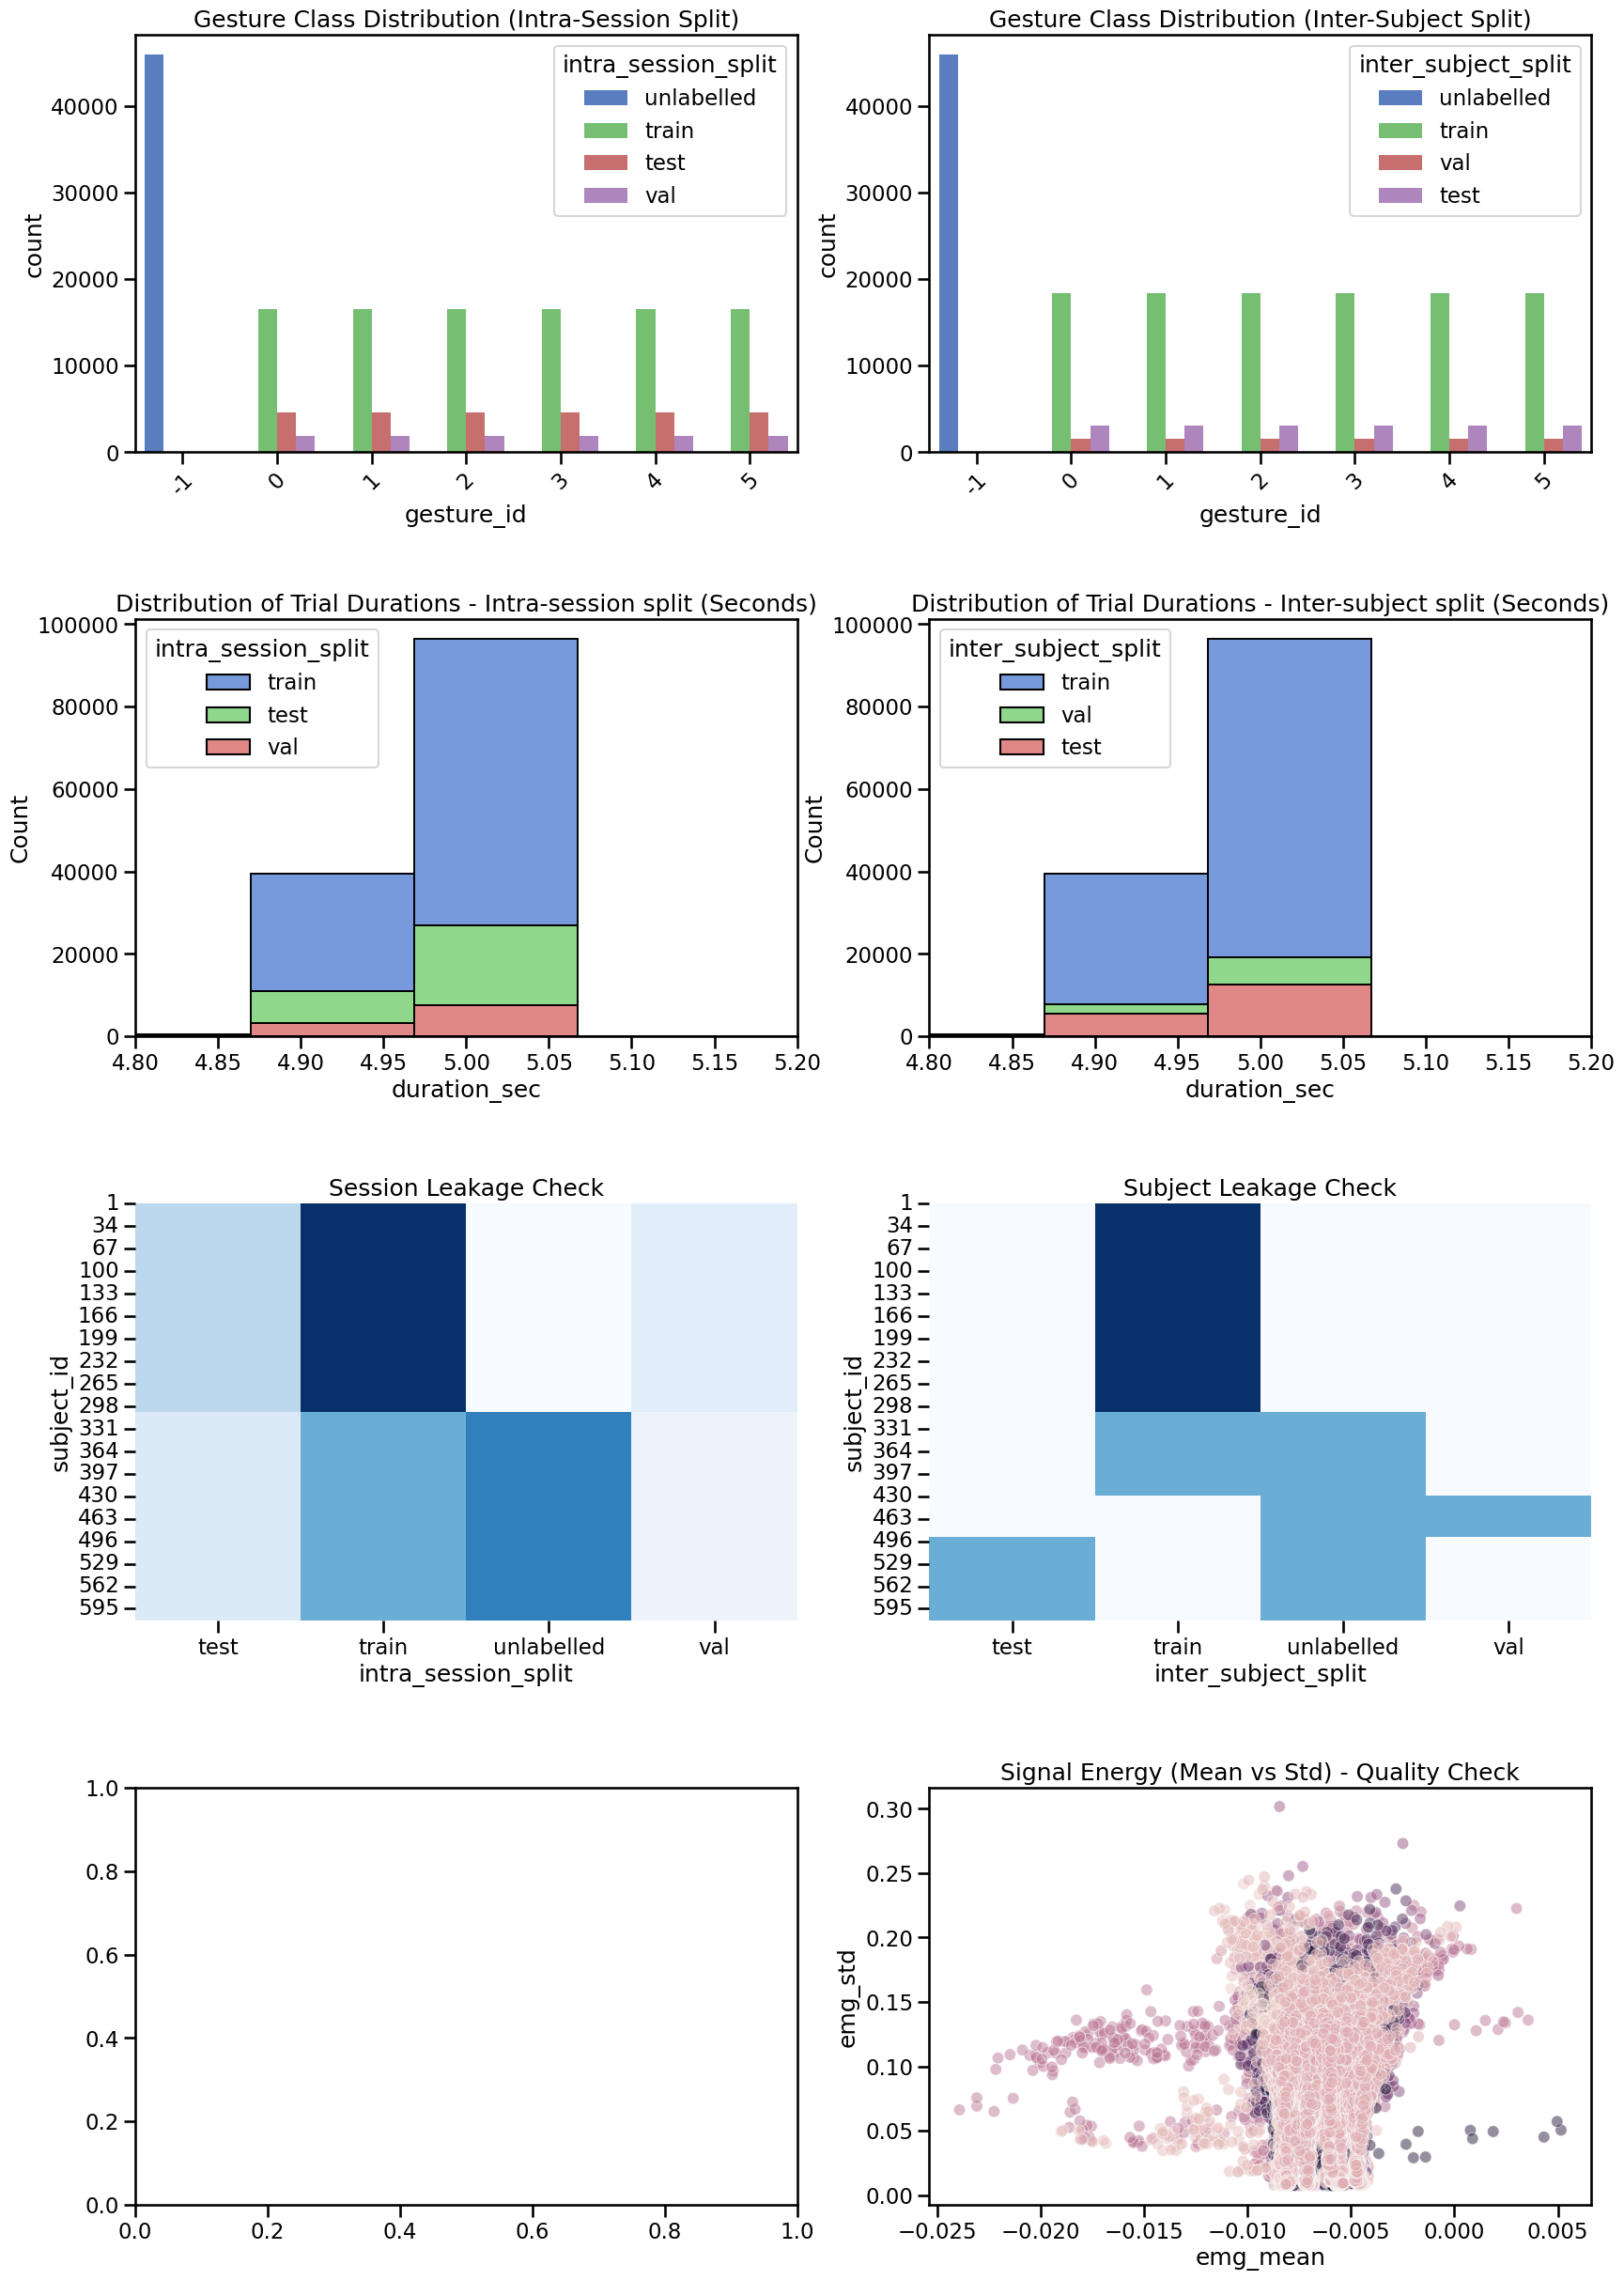

/tmp/ipykernel_4160262/638446165.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=self.df_clean.sort_values('gesture_id'), x='gesture_id', y='duration_sec', palette='husl')


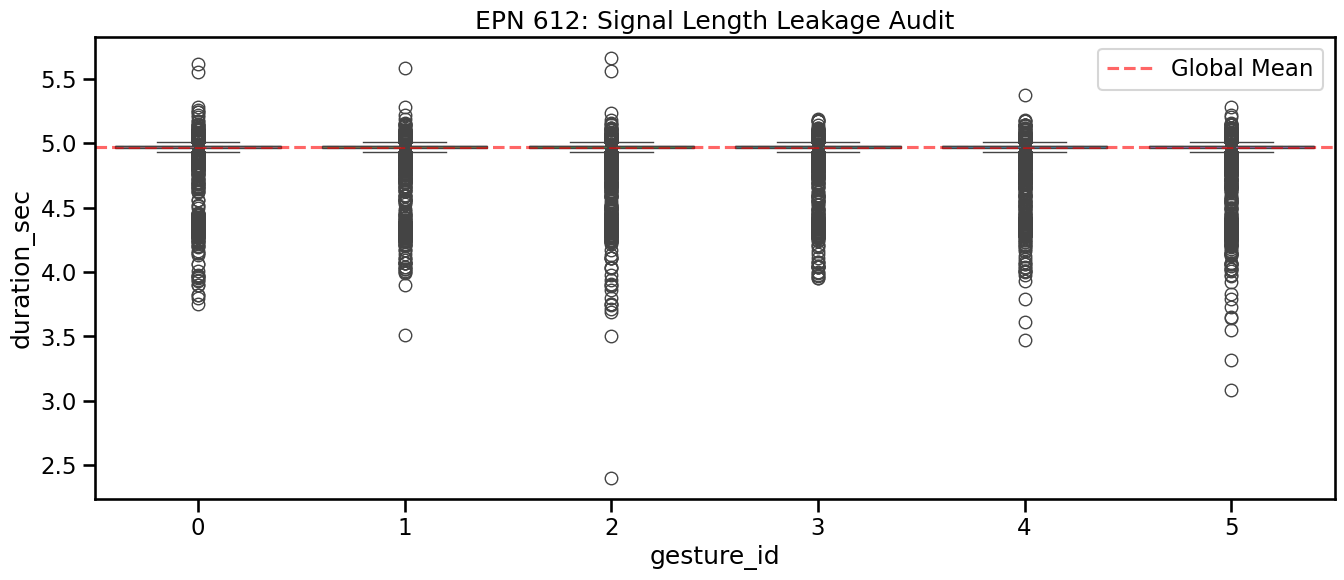


EPN 612 AUDIT REPORT
Total Subjects: 612
Total Trials:   183600
Total EMG Time: 253.45 hours

Split Distribution (intra_session_split):
intra_session_split
train         54.0%
unlabelled    25.0%
test          15.0%
val            6.0%
Name: proportion, dtype: object

Split Distribution (intra_session_split):
intra_session_split
train         54.0%
unlabelled    25.0%
test          15.0%
val            6.0%
Name: proportion, dtype: object

Split Distribution (inter_subject_split):
inter_subject_split
train         59.97%
unlabelled     25.0%
test          10.05%
val            4.98%
Name: proportion, dtype: object

⚠️ WARNING: 306 subjects found in multiple splits: [307, 308, 309, 310, 311]...


In [10]:
auditor = BiosignalAuditor(df, "EPN 612")
auditor.run_full_audit()